# Associative recall benchmark (Idea #1)

**Question.** The first end-to-end milestone (`docs/VISION.md`, decision 5) is *associative recall*: an agent
that is stuck asks its node via MCP (`lgnn_topological_recovery`) and gets back related material. Which
retrieval method should that tool use? Does graph association beat plain vector search?

**Task (dogfooding, decision 2).** Our own git history. For each commit, the *query* is its subject line
(what someone was trying to do) and the *relevant documents* are the source files it changed (where they had
to look). Candidates are all source files in the commit's **parent** snapshot, and every graph signal is built
only from that snapshot and earlier history, so nothing leaks from the future. File names are removed from
the query text.

**Methods.**

| Method | What it does |
|---|---|
| `as_implemented` | What `lgnn_topological_recovery` does today: the first 5 nodes in storage order, ignoring the query (proxy: alphabetical order) |
| `random` | Chance level (mean of 20 shuffles) |
| `history_frequency` | Control: how often a file changed before, ignoring the query |
| `hybrid+frequency` | Control: hybrid fused with change frequency (is the graph gain just popularity?) |
| `lexical` | BM25 over code-aware tokens (path + content) |
| `dense` | MiniLM (`all-MiniLM-L6-v2`, the node's embedding model), max over file chunks |
| `dense_mean` | MiniLM on one mean embedding per file (baseline for `lgnn_smoothed`) |
| `hybrid` | Reciprocal-rank fusion of `lexical` and `dense` |
| `hybrid+graph` | Spreading activation: Personalized PageRank from the top-10 hybrid hits over the code graph (imports + co-change), teleport 0.588, which is LiquidGraph's own long-time limit (see `lgnn_validation`) |
| `hybrid+imports`, `hybrid+cochange` | The same with only one edge type |
| `lgnn_smoothed` | `LiquidGraph.evolve_topology` on the file embeddings over the code graph, then cosine retrieval |

**Metrics.** Recall@5 (share of the changed files in the top 5), Hit@5 (at least one in the top 5, the practical
"did it unblock me" measure), Recall@10, MRR. Means with 95 % bootstrap intervals; paired bootstrap for
differences.

Source of truth is this `.py` (Jupytext); run with `jupytext --to ipynb --update recall_benchmark.py` and
`jupyter nbconvert --to notebook --execute --inplace recall_benchmark.ipynb`.

## Summary (136 queries from 5 repositories, 47 of them from Aethelnet repositories)

| Finding | Evidence (Recall@5, all queries) |
|---|---|
| Today's `lgnn_topological_recovery` is at chance level: it ignores the query | 0.08 vs. random 0.07 |
| Any real retrieval is a big step up | hybrid 0.52, Hit@5 0.82 (+0.44 Recall@5 over today) |
| On code, lexical (BM25) beats dense (MiniLM); hybrid sits in between overall, and is best on the Aethelnet repos | lexical 0.56, dense 0.42; Aethelnet: hybrid 0.65, dense 0.59, lexical 0.55 |
| **Popularity is a strong prior**: files that changed often change again, whatever the query says | `history_frequency` alone 0.57 (Hit@5 0.85), mostly from the C++ repository |
| Spreading activation over the full code graph helps, but the gain is mostly that popularity | hybrid+graph 0.65 vs. hybrid+frequency 0.64 (diff +0.01, CI includes 0) |
| **Co-change association carries real signal beyond popularity** | hybrid+cochange 0.71 vs. hybrid+frequency 0.64 (+0.07, CI [+0.02, +0.12]) |
| Smoothing the *stored* embeddings with LiquidGraph does not help retrieval | lgnn_smoothed 0.35 = dense_mean 0.35 (diff −0.001) |
| In the young Aethelnet histories the graph adds little so far | hybrid 0.65 → graph variants 0.67–0.68, wide CIs |

**Recommendation for the milestone:** make `lgnn_topological_recovery` a *hybrid* retriever (BM25 + MiniLM, rank fusion)
over node texts, then spread activation (Personalized PageRank, teleport ≈ 0.5) over edges that record **things
being used together**, not over similarity edges. On the node, "used together" means *agents retrieving or writing
nodes in the same task*, which is exactly Idea #3 (real Hebbian learning). Keep any popularity prior explicit and
switchable, because it can drown out the query.

In [1]:
import ast
import hashlib
import json
import logging
import math
import os
import re
import subprocess
import sys
import time
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
import warnings  # noqa: E402

warnings.filterwarnings("ignore", module="tqdm")  # IProgress warning prints local install paths

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

REPO = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(REPO))
from aethelnet.liquid_graph import LiquidGraph  # noqa: E402

logging.disable(logging.CRITICAL)
CACHE = Path(os.getenv("AETHELNET_BENCH_CACHE", Path.home() / ".cache" / "aethelnet-bench"))
CACHE.mkdir(parents=True, exist_ok=True)

# Repositories and the exact commits this run used (all public, github.com/aethelnet)
REPOS = {
    "aethelnet-node": "cefee0cad6c64ede448ae45ec3a849c5ed9d84e5",
    "aethelnet-observer": "d4d071fcdf59fc7fa06aa81885a11cb59821fbbe",
    "project-echo": "90fd7d7984c4b1be9201a303e14535a0db63da8e",
    "audio-engine-core": "cdc32ad248f8f18080b7ad58e0195ea7a17a5e60",
    "ygo-edison": "af44c70db305d0d52f5d9d6c0aa4bd36d0c71ee6",
}
AETHELNET_REPOS = {"aethelnet-node", "aethelnet-observer", "project-echo"}
SRC = re.compile(r"\.(py|ts|tsx|js|jsx|vue|sol|cpp|cc|c|h|hpp|astro|svelte)$")
SKIP = re.compile(r"node_modules|/dist/|_archive|/build/|vendor/|third_party|\.min\.js$")
MAX_CHANGED, MIN_POOL, MAX_CHARS = 15, 30, 20000
print("cache directory:", CACHE.name)  # name only, so no local paths end up in the committed outputs

cache directory: bench-data


## Data: queries from git history

In [2]:
def git(repo_dir, *args):
    return subprocess.run(["git", "-C", str(repo_dir), *args], capture_output=True, text=True,
                          encoding="utf-8", errors="replace", check=True).stdout


def ensure_repo(name, sha):
    path = CACHE / name
    if not path.exists():
        subprocess.run(["git", "clone", "-q", "--no-checkout", f"https://github.com/aethelnet/{name}.git", str(path)],
                       check=True)
    try:
        git(path, "cat-file", "-e", sha)
    except subprocess.CalledProcessError:
        git(path, "fetch", "-q", "origin")
    return path


FILE_TOKEN = re.compile(r"\S*\.(py|ts|tsx|js|jsx|vue|sol|cpp|cc|c|h|hpp|astro|svelte|md|json|ya?ml)\b|\S*/\S*")


def clean_query(subject):
    """Remove file names and paths so the query describes intent, not location."""
    return re.sub(r"\s+", " ", FILE_TOKEN.sub(" ", subject)).strip()


def build_queries():
    queries = []
    for name, head in REPOS.items():
        path = ensure_repo(name, head)
        shas = git(path, "rev-list", "--reverse", "--no-merges", head).split()
        history = []  # changed source files of earlier commits (for co-change)
        for sha in shas:
            changed = [f for f in git(path, "show", "--name-only", "--format=", sha).splitlines()
                       if SRC.search(f) and not SKIP.search(f)]
            parents = git(path, "rev-list", "--parents", "-n", "1", sha).split()[1:]
            if parents:
                tree = {}
                for line in git(path, "ls-tree", "-r", parents[0]).splitlines():
                    meta, fpath = line.split("\t", 1)
                    if SRC.search(fpath) and not SKIP.search(fpath):
                        tree[fpath] = meta.split()[2]
                targets = [f for f in changed if f in tree]
                query = clean_query(git(path, "log", "-1", "--format=%s", sha).strip())
                if targets and len(changed) <= MAX_CHANGED and len(tree) >= MIN_POOL and len(query) >= 8:
                    queries.append({"repo": name, "sha": sha, "query": query, "targets": targets,
                                    "pool": tree, "history": list(history)})
            history.append(changed)
    return queries


queries = build_queries()
by_repo = Counter(q["repo"] for q in queries)
print(f"{len(queries)} queries:", dict(by_repo))
print("examples:", [q["query"] for q in queries[:3]])

136 queries: {'aethelnet-node': 33, 'aethelnet-observer': 12, 'project-echo': 2, 'audio-engine-core': 88, 'ygo-edison': 1}
examples: ['Implement continuous node deduplication and merging in GNN loop', 'Simplify node text merging to keep higher confidence text directly', 'Enhance Open Library query to retrieve work']


## Documents: text, tokens, embeddings, code graph (cached per file version)

In [3]:
_blob_text = {}


def blob_text(repo, blob):
    key = (repo, blob)
    if key not in _blob_text:
        _blob_text[key] = git(CACHE / repo, "cat-file", "-p", blob)[:MAX_CHARS]
    return _blob_text[key]


STOP = set("""a an and are as at be by for from has have if in into is it its of on or that the this to was were
will with not no self def return import const let var function class public private static void int float
bool true false none null new this else elif while try except catch finally async await export default""".split())


def tokenize(text):
    out = []
    for word in re.findall(r"[A-Za-z0-9]+", text):
        for part in re.findall(r"[A-Z]?[a-z]+|[A-Z]+(?![a-z])|\d+", word):
            p = part.lower()
            if len(p) > 1 and p not in STOP:
                out.append(p)
    return out


@lru_cache(maxsize=None)
def doc_tokens(repo, path, blob):
    return tuple(tokenize(path.replace("/", " ") + " ") * 2 + tokenize(blob_text(repo, blob)))


def chunks_for(path, text, words_per_chunk=180, max_chunks=8):
    words = text.split()
    pieces = [" ".join(words[i:i + words_per_chunk]) for i in range(0, max(len(words), 1), words_per_chunk)]
    return [f"{path}: {p}" for p in pieces[:max_chunks]] or [path]


from sentence_transformers import SentenceTransformer  # noqa: E402

model = SentenceTransformer("all-MiniLM-L6-v2")
EMB_CACHE = CACHE / "minilm_chunks.npz"
_emb = dict(np.load(EMB_CACHE, allow_pickle=True).items()) if EMB_CACHE.exists() else {}


def embed_docs(items):
    """items: (repo, path, blob). Cached by content hash of the chunk texts."""
    todo = {}
    for repo, path, blob in items:
        key = hashlib.sha1(f"{path}\0{blob}".encode()).hexdigest()
        if key not in _emb:
            todo[key] = chunks_for(path, blob_text(repo, blob))
    if todo:
        flat = [(k, c) for k, cs in todo.items() for c in cs]
        vecs = model.encode([c for _, c in flat], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        grouped = defaultdict(list)
        for (k, _), v in zip(flat, vecs):
            grouped[k].append(v)
        for k, vs in grouped.items():
            _emb[k] = np.stack(vs).astype(np.float32)
        np.savez_compressed(EMB_CACHE, **_emb)
    return {(repo, path): _emb[hashlib.sha1(f"{path}\0{blob}".encode()).hexdigest()] for repo, path, blob in items}


t0 = time.time()
all_items = {(q["repo"], p, b) for q in queries for p, b in q["pool"].items()}
doc_emb = {}
for repo in REPOS:
    items = sorted(i for i in all_items if i[0] == repo)
    embedded = embed_docs(items)
    for (r, p, b) in items:
        doc_emb[(r, p, b)] = embedded[(r, p)]
print(f"{len(all_items)} file versions embedded in {time.time() - t0:.0f}s")

1363 file versions embedded in 0s


In [4]:
PY_IMPORT_EXT = (".py", "/__init__.py")
JS_EXT = ["", ".ts", ".tsx", ".js", ".jsx", ".vue", ".svelte", ".astro", "/index.ts", "/index.js"]


@lru_cache(maxsize=None)
def raw_imports(repo, path, blob):
    """Import names (Python) or import/include specs (other languages) of one file version."""
    text = blob_text(repo, blob)
    here = path.rsplit("/", 1)[0] if "/" in path else ""
    if not path.endswith(".py"):
        return tuple(re.findall(r"""(?:import[^'"]*?from\s*|import\s*|require\(\s*|#include\s*)["']([^"']+)["']""", text))
    try:
        tree = ast.parse(text)
    except (SyntaxError, ValueError):
        return ()
    names = []
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            names += [a.name for a in node.names]
        elif isinstance(node, ast.ImportFrom):
            base = node.module or ""
            if node.level:
                pkg = here.split("/") if here else []
                pkg = pkg[: len(pkg) - (node.level - 1)] if node.level > 1 else pkg
                base = ".".join([*pkg, base] if base else pkg)
            names += [base] + [f"{base}.{a.name}" for a in node.names]
    return tuple(names)


def import_edges(repo, pool):
    """Undirected import/include edges between files of one snapshot."""
    paths = set(pool)
    by_module = {}
    for p in paths:
        if p.endswith(".py"):
            mod = p[:-3].replace("/", ".")
            by_module[mod[:-9] if mod.endswith(".__init__") else mod] = p
    basenames = defaultdict(list)
    for p in paths:
        basenames[p.rsplit("/", 1)[-1]].append(p)
    edges = set()
    for p, blob in pool.items():
        here = p.rsplit("/", 1)[0] if "/" in p else ""
        targets = set()
        if p.endswith(".py"):
            for n in raw_imports(repo, p, blob):
                # `from pkg.mod import x` names pkg.mod and pkg.mod.x; repos may nest packages
                # under a folder (e.g. src-python/services/...), so also match by suffix
                for mod, target in by_module.items():
                    if mod == n or mod.endswith("." + n):
                        targets.add(target)
        else:
            for spec in raw_imports(repo, p, blob):
                if spec.startswith("."):
                    base = os.path.normpath(os.path.join(here, spec)).replace("\\", "/")
                    for ext in JS_EXT:
                        if base + ext in paths:
                            targets.add(base + ext)
                            break
                else:
                    name = spec.rsplit("/", 1)[-1]
                    cands = basenames.get(name, [])
                    if len(cands) == 1:
                        targets.add(cands[0])
        for t in targets:
            if t != p:
                edges.add(tuple(sorted((p, t))))
    return edges


def cochange_edges(history, pool, max_files=20):
    weights = Counter()
    for changed in history:
        files = [f for f in changed if f in pool]
        if 2 <= len(files) <= max_files:
            w = 1.0 / (len(files) - 1)
            for i in range(len(files)):
                for j in range(i + 1, len(files)):
                    weights[tuple(sorted((files[i], files[j])))] += w
    return weights

## Retrieval methods

In [5]:
def bm25_scores(query_tokens, docs_tokens, k1=1.2, b=0.75):
    n = len(docs_tokens)
    lengths = np.array([len(d) for d in docs_tokens], dtype=float)
    avg = lengths.mean() if n else 1.0
    df = Counter(t for d in docs_tokens for t in set(d))
    counts = [Counter(d) for d in docs_tokens]
    scores = np.zeros(n)
    for t in set(query_tokens):
        if t not in df:
            continue
        idf = math.log(1 + (n - df[t] + 0.5) / (df[t] + 0.5))
        for i, c in enumerate(counts):
            tf = c.get(t, 0)
            if tf:
                scores[i] += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * lengths[i] / avg))
    return scores


def ranks_from_scores(scores):
    order = np.argsort(-scores, kind="stable")
    ranks = np.empty(len(scores), dtype=int)
    ranks[order] = np.arange(1, len(scores) + 1)
    return ranks


def rrf(*score_lists, k=60):
    return sum(1.0 / (k + ranks_from_scores(s)) for s in score_lists)


def ppr_from_seeds(seed_scores, W, teleport=0.588, top=10, iters=60):
    """Spreading activation: Personalized PageRank from the top-`top` hits (weight 1/rank) over graph W."""
    n = len(seed_scores)
    seed = np.zeros(n)
    for rank, idx in enumerate(np.argsort(-seed_scores, kind="stable")[:top], start=1):
        seed[idx] = 1.0 / rank
    seed /= seed.sum()
    deg = np.asarray(W.sum(axis=1)).ravel()
    P = W / np.where(deg > 0, deg, 1)[:, None]
    r = seed.copy()
    for _ in range(iters):
        dangling = r[deg == 0].sum()
        r = teleport * seed + (1 - teleport) * (P.T @ r + dangling * seed)
    return r + 1e-9 * seed_scores / (np.abs(seed_scores).max() + 1e-12)  # stable tie-break by the seed method


def lgnn_smoothed_scores(q_vec, file_vecs, W):
    n, d = file_vecs.shape
    torch.manual_seed(0)
    g = LiquidGraph(hidden_dim=d, resonance_threshold=1.01)
    for i in range(n):
        g.add_node(f"f{i}", torch.tensor(file_vecs[i]))
    rows, cols = np.nonzero(np.triu(W, 1))
    for i, j in zip(rows, cols):
        g.nx_graph.add_edge(f"f{i}", f"f{j}", weight=float(W[i, j]))
    g.evolve_topology(compute_time=1.0)
    evolved = torch.stack([g.get_node_embedding(f"f{i}") for i in range(n)]).numpy()
    return evolved @ q_vec


def evaluate(query):
    repo, paths = query["repo"], sorted(query["pool"])
    blobs = [query["pool"][p] for p in paths]
    n = len(paths)
    index = {p: i for i, p in enumerate(paths)}
    target_idx = [index[t] for t in query["targets"]]

    q_vec = model.encode(query["query"], normalize_embeddings=True)
    chunk_embs = [doc_emb[(repo, p, b)] for p, b in zip(paths, blobs)]
    dense = np.array([float((c @ q_vec).max()) for c in chunk_embs])
    mean_vecs = np.stack([F.normalize(torch.tensor(c.mean(axis=0)), dim=0).numpy() for c in chunk_embs])
    dense_mean = mean_vecs @ q_vec
    lexical = bm25_scores(tokenize(query["query"]), [doc_tokens(repo, p, b) for p, b in zip(paths, blobs)])
    hybrid = rrf(lexical, dense)

    W_imp = np.zeros((n, n))
    for a, b in import_edges(repo, dict(zip(paths, blobs))):
        W_imp[index[a], index[b]] = W_imp[index[b], index[a]] = 1.0
    W_co = np.zeros((n, n))
    for (a, b), w in cochange_edges(query["history"], index).items():
        W_co[index[a], index[b]] = W_co[index[b], index[a]] = w
    W_all = W_imp + W_co

    # Popularity control: files that changed often tend to change again, whatever the query says.
    # If co-change helps only through popularity, hybrid+frequency should match hybrid+cochange.
    freq = Counter(f for changed in query["history"] for f in changed)
    frequency = np.array([freq.get(p, 0) for p in paths], dtype=float)

    scores = {
        "history_frequency": frequency,
        "hybrid+frequency": rrf(lexical, dense, frequency),
        "as_implemented": -np.arange(n, dtype=float),  # alphabetical order, query ignored
        "lexical": lexical,
        "dense": dense,
        "dense_mean": dense_mean,
        "hybrid": hybrid,
        "hybrid+graph": ppr_from_seeds(hybrid, W_all),
        "hybrid+imports": ppr_from_seeds(hybrid, W_imp),
        "hybrid+cochange": ppr_from_seeds(hybrid, W_co),
        "lgnn_smoothed": lgnn_smoothed_scores(q_vec, mean_vecs, W_all),
    }
    result = {name: metrics(ranks_from_scores(s)[target_idx]) for name, s in scores.items()}
    rng = np.random.default_rng(int(query["sha"][:8], 16))
    shuffles = [metrics(ranks_from_scores(rng.random(n))[target_idx]) for _ in range(20)]
    result["random"] = {k: float(np.mean([s[k] for s in shuffles])) for k in shuffles[0]}
    result["_graph"] = {"n": n, "import_edges": int((W_imp > 0).sum() // 2), "cochange_edges": int((W_co > 0).sum() // 2)}
    result["_hybrid_scores"], result["_W"], result["_targets"] = hybrid, W_all, target_idx
    return result


def metrics(target_ranks):
    target_ranks = np.asarray(target_ranks)
    return {
        "recall@5": float((target_ranks <= 5).mean()),
        "hit@5": float((target_ranks <= 5).any()),
        "recall@10": float((target_ranks <= 10).mean()),
        "mrr": float(1.0 / target_ranks.min()),
    }

## Run

In [6]:
t0 = time.time()
results = [evaluate(q) for q in queries]
print(f"evaluated {len(results)} queries in {time.time() - t0:.0f}s")
g = [r["_graph"] for r in results]
print("pool size median", int(np.median([x["n"] for x in g])),
      "| import edges median", int(np.median([x["import_edges"] for x in g])),
      "| co-change edges median", int(np.median([x["cochange_edges"] for x in g])))

METHODS = ["as_implemented", "random", "history_frequency", "lexical", "dense", "dense_mean", "hybrid",
           "hybrid+frequency", "hybrid+graph", "hybrid+imports", "hybrid+cochange", "lgnn_smoothed"]
METRICS = ["recall@5", "hit@5", "recall@10", "mrr"]
rng = np.random.default_rng(0)


def table(subset):
    idx = np.array(subset)
    boot = rng.integers(0, len(idx), size=(2000, len(idx)))
    out = {}
    for m in METHODS:
        out[m] = {}
        for metric in METRICS:
            vals = np.array([results[i][m][metric] for i in idx])
            means = vals[boot].mean(axis=1)
            out[m][metric] = (vals.mean(), *np.percentile(means, [2.5, 97.5]))
    return out


def print_table(title, subset):
    t = table(subset)
    print(f"\n{title} (n={len(subset)} queries)")
    print(f"{'method':<16}" + "".join(f"{m:>22}" for m in METRICS))
    for m in METHODS:
        print(f"{m:<16}" + "".join(f"{t[m][k][0]:>8.3f} [{t[m][k][1]:.2f},{t[m][k][2]:.2f}]" for k in METRICS))
    return t


all_idx = list(range(len(results)))
aeth_idx = [i for i, q in enumerate(queries) if q["repo"] in AETHELNET_REPOS]
other_idx = [i for i, q in enumerate(queries) if q["repo"] not in AETHELNET_REPOS]
T_all = print_table("All repositories", all_idx)
T_aeth = print_table("Aethelnet repositories only", aeth_idx)
T_other = print_table("Other repositories (audio-engine-core, ygo-edison)", other_idx)

evaluated 136 queries in 197s
pool size median 74 | import edges median 154 | co-change edges median 297

All repositories (n=136 queries)
method                        recall@5                 hit@5             recall@10                   mrr
as_implemented     0.078 [0.04,0.12]   0.125 [0.07,0.18]   0.330 [0.27,0.39]   0.113 [0.10,0.13]
random             0.068 [0.06,0.08]   0.178 [0.15,0.20]   0.135 [0.12,0.15]   0.133 [0.12,0.15]
history_frequency   0.574 [0.52,0.63]   0.846 [0.79,0.90]   0.643 [0.59,0.70]   0.769 [0.71,0.83]
lexical            0.559 [0.49,0.62]   0.838 [0.78,0.90]   0.717 [0.66,0.77]   0.573 [0.51,0.64]
dense              0.420 [0.36,0.48]   0.713 [0.63,0.79]   0.555 [0.49,0.61]   0.538 [0.47,0.60]
dense_mean         0.352 [0.29,0.42]   0.647 [0.57,0.73]   0.486 [0.43,0.55]   0.489 [0.42,0.55]
hybrid             0.515 [0.45,0.58]   0.816 [0.75,0.88]   0.693 [0.64,0.75]   0.585 [0.52,0.65]
hybrid+frequency   0.638 [0.58,0.70]   0.890 [0.84,0.94]   0.792 [0.74,0.84]


Aethelnet repositories only (n=47 queries)
method                        recall@5                 hit@5             recall@10                   mrr
as_implemented     0.196 [0.10,0.30]   0.298 [0.17,0.43]   0.489 [0.36,0.62]   0.157 [0.12,0.20]
random             0.066 [0.05,0.08]   0.123 [0.09,0.16]   0.119 [0.09,0.14]   0.101 [0.08,0.12]
history_frequency   0.468 [0.34,0.60]   0.617 [0.49,0.74]   0.548 [0.42,0.67]   0.527 [0.40,0.66]
lexical            0.552 [0.42,0.68]   0.702 [0.57,0.83]   0.638 [0.51,0.76]   0.430 [0.33,0.53]
dense              0.588 [0.47,0.71]   0.766 [0.64,0.87]   0.713 [0.60,0.82]   0.552 [0.45,0.65]
dense_mean         0.443 [0.32,0.56]   0.638 [0.49,0.77]   0.540 [0.42,0.66]   0.471 [0.36,0.58]
hybrid             0.654 [0.53,0.77]   0.809 [0.68,0.91]   0.745 [0.64,0.85]   0.568 [0.46,0.67]
hybrid+frequency   0.652 [0.52,0.77]   0.766 [0.64,0.87]   0.746 [0.63,0.85]   0.573 [0.47,0.68]
hybrid+graph       0.670 [0.55,0.79]   0.851 [0.74,0.94]   0.761 [0.65,0.8

In [7]:
def paired(a, b, metric, subset, n_boot=5000):
    idx = np.array(subset)
    diff = np.array([results[i][a][metric] - results[i][b][metric] for i in idx])
    boot = np.random.default_rng(1).integers(0, len(idx), size=(n_boot, len(idx)))
    means = diff[boot].mean(axis=1)
    return diff.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5), (means > 0).mean()

print("Paired differences (mean, 95% CI, P(diff>0)) on all queries:")
for a, b in [("dense", "lexical"), ("hybrid", "dense"), ("hybrid", "lexical"), ("hybrid+graph", "hybrid"),
             ("hybrid+cochange", "hybrid"), ("hybrid+imports", "hybrid"), ("hybrid+frequency", "hybrid"),
             ("hybrid+cochange", "hybrid+frequency"), ("hybrid+graph", "hybrid+frequency"),
             ("lgnn_smoothed", "dense_mean"), ("hybrid", "as_implemented")]:
    for metric in ("recall@5", "hit@5"):
        d, lo, hi, p = paired(a, b, metric, all_idx)
        print(f"  {a:>16} - {b:<15} {metric:<9} {d:+.3f} [{lo:+.3f}, {hi:+.3f}]  P={p:.2f}")

Paired differences (mean, 95% CI, P(diff>0)) on all queries:


             dense - lexical         recall@5  -0.139 [-0.203, -0.075]  P=0.00
             dense - lexical         hit@5     -0.125 [-0.206, -0.044]  P=0.00
            hybrid - dense           recall@5  +0.095 [+0.045, +0.145]  P=1.00
            hybrid - dense           hit@5     +0.103 [+0.037, +0.169]  P=1.00
            hybrid - lexical         recall@5  -0.044 [-0.096, +0.007]  P=0.05
            hybrid - lexical         hit@5     -0.022 [-0.088, +0.037]  P=0.20
      hybrid+graph - hybrid          recall@5  +0.136 [+0.092, +0.183]  P=1.00
      hybrid+graph - hybrid          hit@5     +0.110 [+0.051, +0.176]  P=1.00
   hybrid+cochange - hybrid          recall@5  +0.196 [+0.150, +0.244]  P=1.00
   hybrid+cochange - hybrid          hit@5     +0.118 [+0.066, +0.176]  P=1.00


    hybrid+imports - hybrid          recall@5  +0.084 [+0.044, +0.128]  P=1.00
    hybrid+imports - hybrid          hit@5     +0.066 [+0.015, +0.118]  P=1.00
  hybrid+frequency - hybrid          recall@5  +0.123 [+0.061, +0.185]  P=1.00
  hybrid+frequency - hybrid          hit@5     +0.074 [+0.000, +0.147]  P=0.97
   hybrid+cochange - hybrid+frequency recall@5  +0.073 [+0.023, +0.123]  P=1.00
   hybrid+cochange - hybrid+frequency hit@5     +0.044 [+0.000, +0.096]  P=0.95
      hybrid+graph - hybrid+frequency recall@5  +0.013 [-0.038, +0.066]  P=0.70
      hybrid+graph - hybrid+frequency hit@5     +0.037 [-0.015, +0.088]  P=0.89
     lgnn_smoothed - dense_mean      recall@5  -0.001 [-0.013, +0.010]  P=0.47
     lgnn_smoothed - dense_mean      hit@5     -0.007 [-0.037, +0.015]  P=0.17
            hybrid - as_implemented  recall@5  +0.437 [+0.373, +0.499]  P=1.00
            hybrid - as_implemented  hit@5     +0.691 [+0.603, +0.772]  P=1.00


## Chart: Recall@5 by method

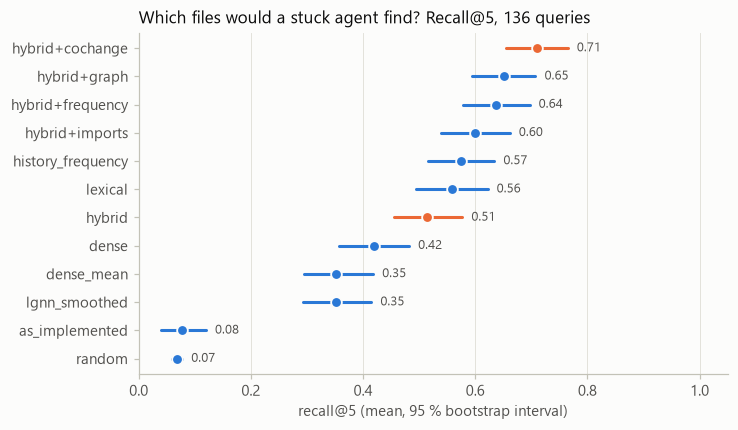

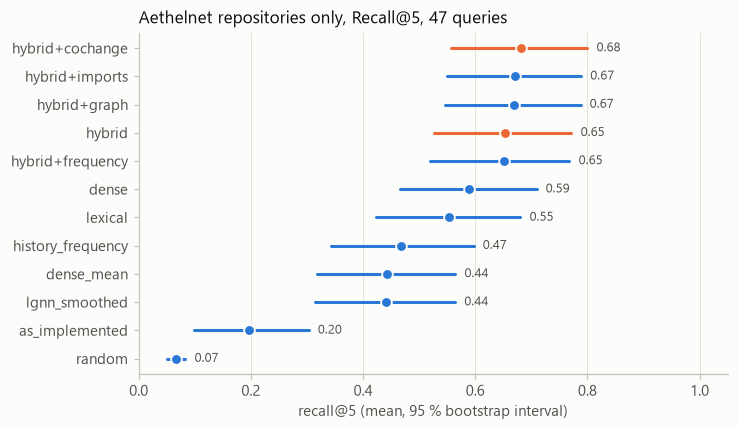

In [8]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9.5})


def dot_chart(t, metric, title, highlight=("hybrid", "hybrid+cochange")):
    order = sorted(METHODS, key=lambda m: t[m][metric][0])
    fig, ax = plt.subplots(figsize=(6.8, 4.0), dpi=110)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.grid(True, axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    for y, m in enumerate(order):
        mean, lo, hi = t[m][metric]
        color = ORANGE if m in highlight else BLUE
        ax.plot([lo, hi], [y, y], color=color, linewidth=2, solid_capstyle="round")
        ax.plot(mean, y, "o", color=color, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.2)
        ax.annotate(f"{mean:.2f}", (hi, y), xytext=(6, 0), textcoords="offset points", va="center",
                    color=INK2, fontsize=8.5)
    ax.set_yticks(range(len(order)), order)
    ax.tick_params(colors=AXIS, labelcolor=INK2)
    ax.set_xlim(0, 1.05)
    ax.set_xlabel(f"{metric} (mean, 95 % bootstrap interval)", color=INK2)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    fig.tight_layout()
    plt.show()


dot_chart(T_all, "recall@5", f"Which files would a stuck agent find? Recall@5, {len(all_idx)} queries")
dot_chart(T_aeth, "recall@5", f"Aethelnet repositories only, Recall@5, {len(aeth_idx)} queries")

## Sensitivity: how much graph diffusion?

The teleport 0.588 above was fixed in advance (LiquidGraph's implied value). This sweep shows how the result
depends on it, so the choice can be revisited without overfitting the main table to this data set.

teleport 1.0   recall@5 0.515
teleport 0.9   recall@5 0.551
teleport 0.8   recall@5 0.587
teleport 0.7   recall@5 0.607
teleport 0.588 recall@5 0.651
teleport 0.5   recall@5 0.686
teleport 0.4   recall@5 0.673
teleport 0.3   recall@5 0.689
teleport 0.2   recall@5 0.679


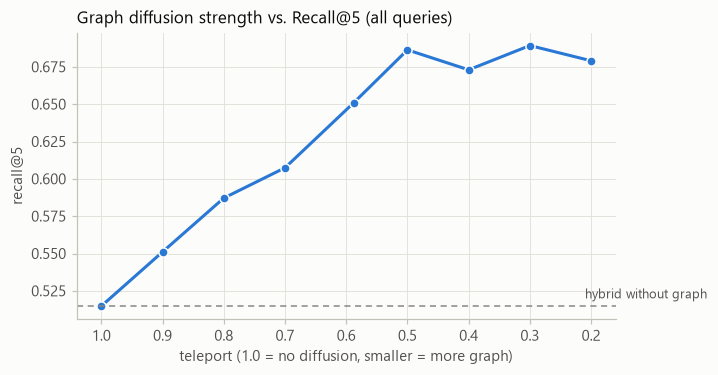

In [9]:
teleports = [1.0, 0.9, 0.8, 0.7, 0.588, 0.5, 0.4, 0.3, 0.2]
sweep = []
for tp in teleports:
    vals = [metrics(ranks_from_scores(ppr_from_seeds(r["_hybrid_scores"], r["_W"], teleport=tp))[r["_targets"]])["recall@5"]
            for r in results]
    sweep.append(float(np.mean(vals)))
for tp, v in zip(teleports, sweep):
    print(f"teleport {tp:<5} recall@5 {v:.3f}")

fig, ax = plt.subplots(figsize=(6.6, 3.5), dpi=110)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
ax.plot(teleports, sweep, color=BLUE, linewidth=2, marker="o", markersize=6, markeredgecolor=SURFACE)
ax.axhline(T_all["hybrid"]["recall@5"][0], color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate("hybrid without graph", (0.21, T_all["hybrid"]["recall@5"][0]), xytext=(0, 5), textcoords="offset points",
            color=INK2, fontsize=8.5)
ax.invert_xaxis()
ax.set_xlabel("teleport (1.0 = no diffusion, smaller = more graph)", color=INK2)
ax.set_ylabel("recall@5", color=INK2)
ax.tick_params(colors=AXIS, labelcolor=INK2)
ax.set_title("Graph diffusion strength vs. Recall@5 (all queries)", loc="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

## Conclusions

1. **Ship real retrieval first.** Replacing "first five nodes" with hybrid BM25 + MiniLM retrieval is the largest,
   least risky gain (+0.44 Recall@5, +0.69 Hit@5).
2. **Association helps when the edges mean "used together".** Co-change edges beat a popularity control; import edges
   and the mixed graph mostly rediscover popularity. For agent memory, the analogue of co-change is co-retrieval /
   co-editing by agents within one task, which the node can log now that writes carry an agent id (node#6).
3. **Spread activation at query time, keep stored meaning anchored.** Diffusing *relevance* (PPR from the top hits)
   helps; diffusing the *stored embeddings* (LiquidGraph smoothing at default settings) does not. This fits the
   tether finding in `lgnn_validation` §8: concepts stay anchored, activation moves.
4. **Teleport ≈ 0.5** works better than the a-priori 0.588 here (0.69 vs. 0.65 with the full graph); 0.2–0.5 is a
   plateau. Revisit on node data before fixing it.
5. **Popularity is powerful and dangerous.** It wins on repositories with a few hot files and can bury the query.
   Make it a separate, weighted signal that agents can switch off.

**Limitations.** This is a proxy: files instead of concept nodes, commit subjects instead of real "stuck" questions.
89 of 136 queries come from one C++ repository; the Aethelnet subset (47) has wide intervals. Hyperparameters (top-10
seeds, RRF k=60, BM25 defaults, teleport 0.588) were fixed before running; only the teleport sweep explores one.
The next step is the same comparison on the node's own graph once agents log co-retrieval events.